# Heart Disease Project (suprivise learining - Classification)

## Steps 
* EDA
* Visualisation Data
* Data Preprocessing
* Train-Test split
* model training
* Evaluation
* Deployement

In [1]:
# Importation 
import numpy as np 
import pandas as pd 

import seaborn as sns
import matplotlib.pyplot as plt 

In [2]:
!pip install joblib streamlit

In [4]:
import joblib
import streamlit

from sklearn.model_selection import train_test_split , cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score , confusion_matrix, classification_report
from sklearn.preprocessing import StandardScaler
import warnings
warnings.filterwarnings('ignore')

In [5]:
df = pd.read_csv('heart_disease_data.csv')

### Eda

In [6]:
df.shape

(303, 14)

In [8]:
df.head(20)

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1
5,57,1,0,140,192,0,1,148,0,0.4,1,0,1,1
6,56,0,1,140,294,0,0,153,0,1.3,1,0,2,1
7,44,1,1,120,263,0,1,173,0,0.0,2,0,3,1
8,52,1,2,172,199,1,1,162,0,0.5,2,0,3,1
9,57,1,2,150,168,0,1,174,0,1.6,2,0,2,1


In [10]:
df.info() # no Nan & all features are nummerical

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 303 entries, 0 to 302
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       303 non-null    int64  
 1   sex       303 non-null    int64  
 2   cp        303 non-null    int64  
 3   trestbps  303 non-null    int64  
 4   chol      303 non-null    int64  
 5   fbs       303 non-null    int64  
 6   restecg   303 non-null    int64  
 7   thalach   303 non-null    int64  
 8   exang     303 non-null    int64  
 9   oldpeak   303 non-null    float64
 10  slope     303 non-null    int64  
 11  ca        303 non-null    int64  
 12  thal      303 non-null    int64  
 13  target    303 non-null    int64  
dtypes: float64(1), int64(13)
memory usage: 33.3 KB


In [11]:
# look for missing values Nan
print('Missing values ',df.isnull().sum()) # count nan => which is 0 Nan
print(df['target'].value_counts())

# count how many 1 & 0 in target columns
print(f'balance:{df['target'].value_counts()[1]/df['target'].value_counts()[0]:.2f}:1')

Missing values  age         0
sex         0
cp          0
trestbps    0
chol        0
fbs         0
restecg     0
thalach     0
exang       0
oldpeak     0
slope       0
ca          0
thal        0
target      0
dtype: int64
target
1    165
0    138
Name: count, dtype: int64
balance:1.20:1


### Visualisation Data

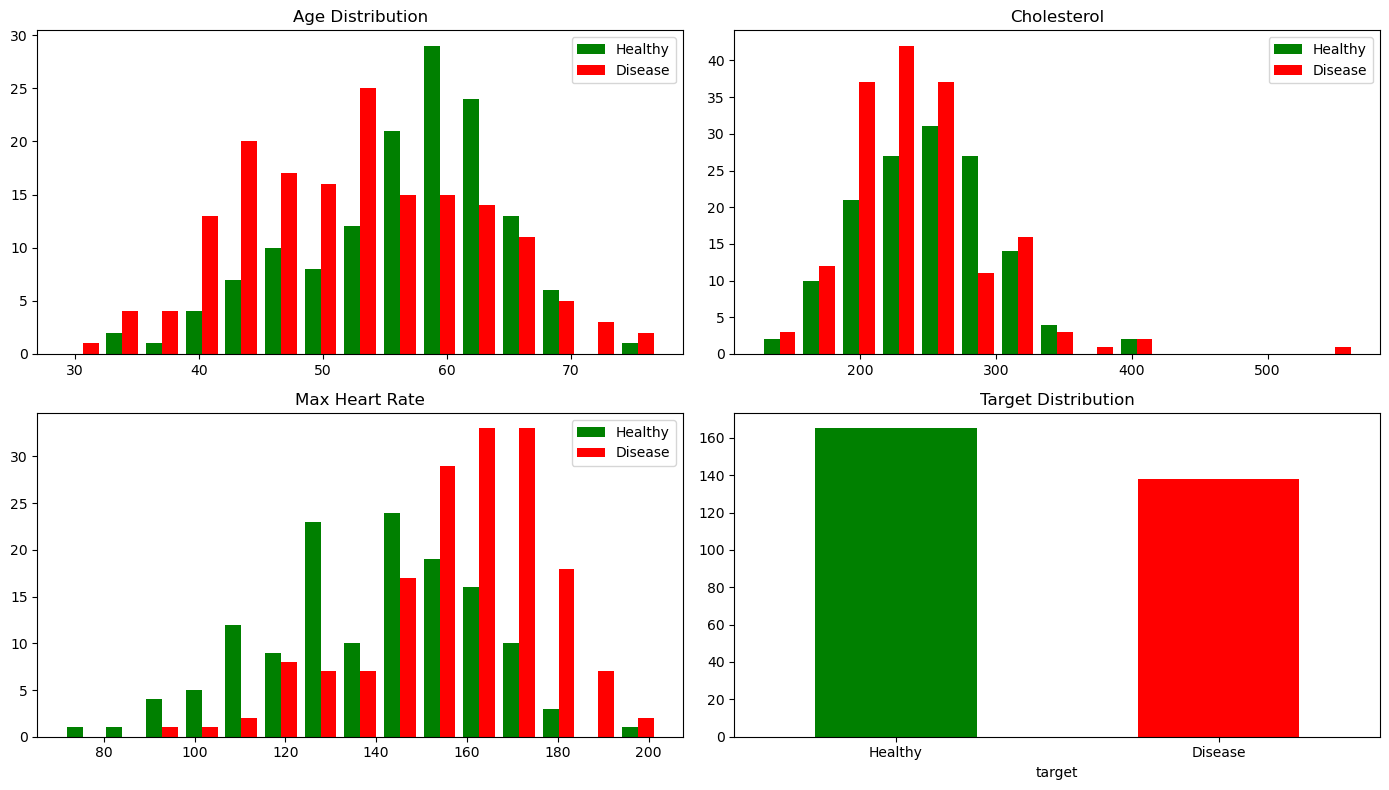

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))

# Top-left: Age distribution
axes[0, 0].hist([df[df['target'] == 0]['age'], 
                 df[df['target'] == 1]['age']], 
                label=['Healthy', 'Disease'], 
                bins=15, 
                color=['green', 'red'])
axes[0, 0].set_title('Age Distribution')
axes[0, 0].legend()

# Top-right: Cholesterol distribution
axes[0, 1].hist([df[df['target'] == 0]['chol'], 
                 df[df['target'] == 1]['chol']], 
                label=['Healthy', 'Disease'], 
                bins=15, 
                color=['green', 'red'])
axes[0, 1].set_title('Cholesterol')
axes[0, 1].legend()

# Bottom-left: Max heart rate distribution
axes[1, 0].hist([df[df['target'] == 0]['thalach'], 
                 df[df['target'] == 1]['thalach']], 
                label=['Healthy', 'Disease'], 
                bins=15, 
                color=['green', 'red'])
axes[1, 0].set_title('Max Heart Rate')
axes[1, 0].legend()

# Bottom-right: Target distribution bar chart
df['target'].value_counts().plot(kind='bar', 
                                 ax=axes[1, 1], 
                                 color=['green', 'red'])
axes[1, 1].set_title('Target Distribution')
axes[1, 1].set_xticklabels(['Healthy', 'Disease'], rotation=0)

plt.tight_layout()
plt.show()

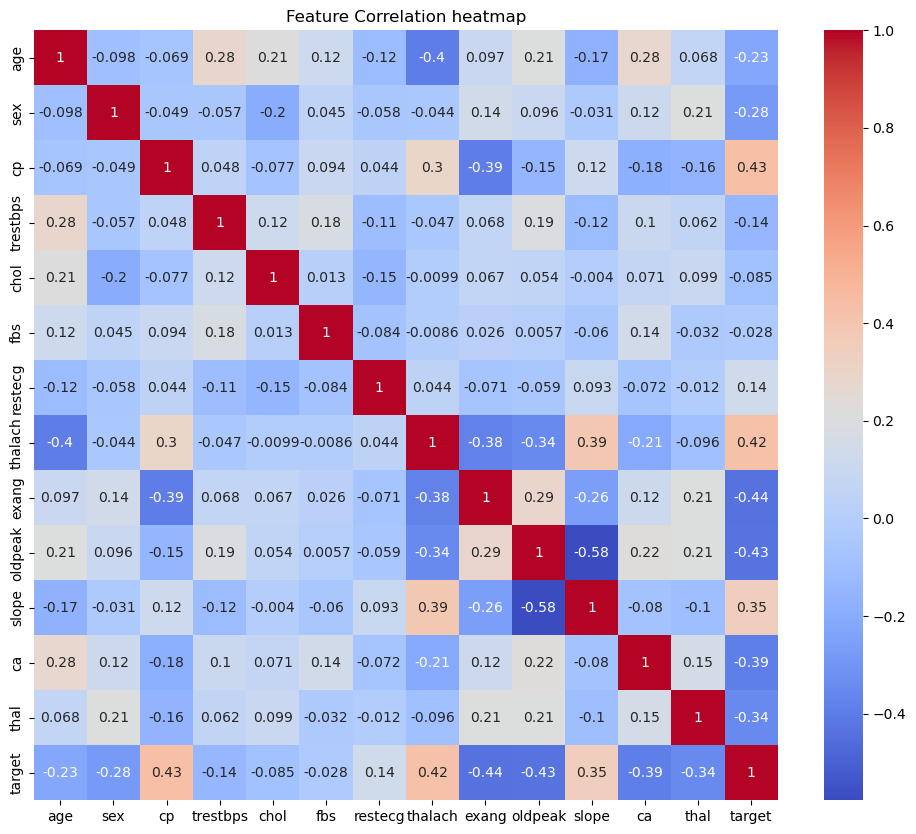

In [14]:
plt.figure(figsize=(12,10))
sns.heatmap(df.corr(),annot=True , cmap='coolwarm')
plt.title('Feature Correlation heatmap')
plt.show()

### Train-Test split

In [16]:
x= df.drop(['target'],axis=1)
y = df['target']

x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.25,stratify=y,random_state=42)

In [17]:
x_train.shape

(227, 13)

In [18]:
x_test.shape

(76, 13)

### Data Preprocessing

In [19]:
# scalling data

scaler = StandardScaler()
x_train_scaled =scaler.fit_transform(x_train)
x_test_scaled =scaler.fit_transform(x_test)

joblib.dump(scaler,'heart_scaler.pkl')

['heart_scaler.pkl']

### modelling

In [20]:
model = LogisticRegression(max_iter=1000, random_state=42)
score =cross_val_score(model,x_train_scaled,y_train,cv=5, scoring='accuracy')
print(f'{score.mean():.4f} (+/- {score.std():.4f})')

0.8372 (+/- 0.0470)


In [21]:
model.fit(x_train_scaled,y_train)

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multi

In [22]:
y_train_pred = model.predict(x_train_scaled)
y_test_pred = model.predict(x_test_scaled)

train_acc =accuracy_score(y_train,y_train_pred)
test_acc =accuracy_score(y_test,y_test_pred)

print(train_acc) #score 86%
print(test_acc) # score 76%
print(classification_report(y_test,y_test_pred,target_names=['Healthy','Disease']))

0.8634361233480177
0.7631578947368421
              precision    recall  f1-score   support

     Healthy       0.79      0.66      0.72        35
     Disease       0.74      0.85      0.80        41

    accuracy                           0.76        76
   macro avg       0.77      0.76      0.76        76
weighted avg       0.77      0.76      0.76        76



Text(0.5, 36.72222222222221, 'Predicted')

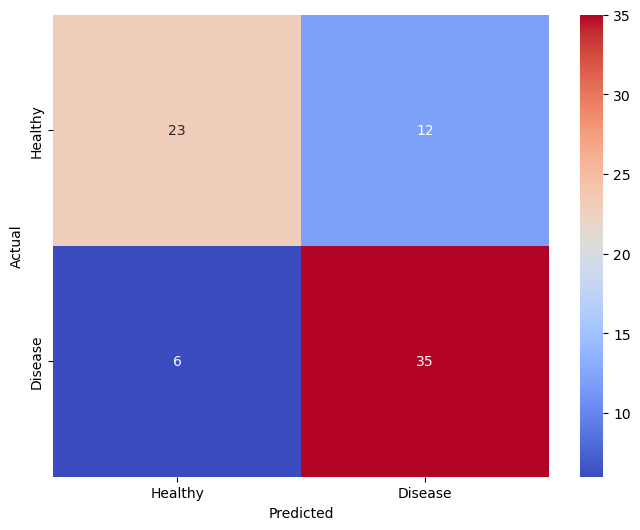

In [26]:
# confusion matrix 

cm = confusion_matrix(y_test,y_test_pred)
plt.figure(figsize=(8,6))
sns.heatmap(cm,annot=True , cmap='coolwarm', xticklabels=['Healthy','Disease'], yticklabels=['Healthy','Disease'])
plt.ylabel('Actual')
plt.xlabel('Predicted')

In [27]:
model_data={
    'model':model,
    'feature_names':x.columns.tolist()
}
joblib.dump(model_data,'heart_disease_model.pkl')

['heart_disease_model.pkl']